In [8]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

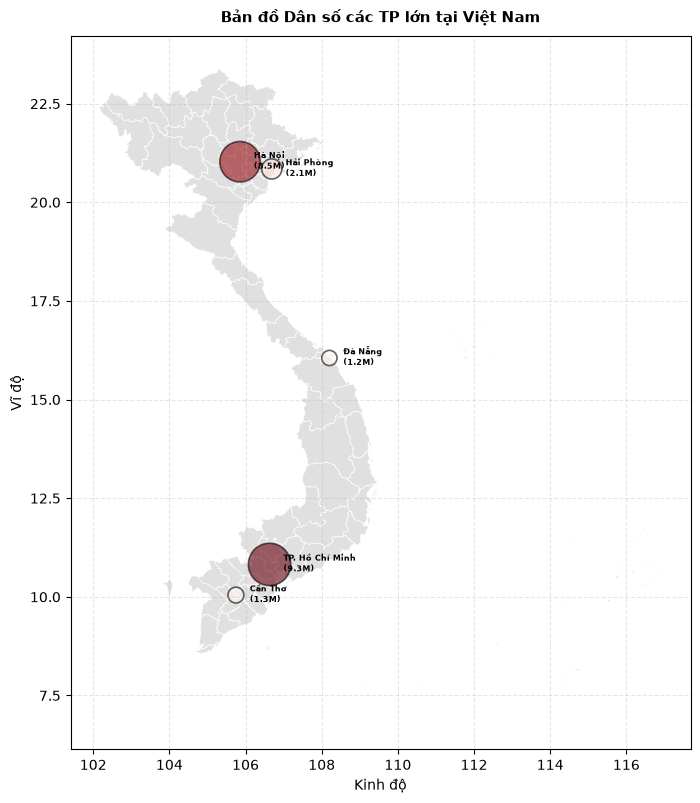

In [19]:
data = {
    'City': ['Hà Nội', 'Hải Phòng', 'Đà Nẵng',
             'TP. Hồ Chí Minh', 'Cần Thơ'],
    'Lat': [21.0285, 20.8449, 16.0544, 10.8231, 10.0452],
    'Lon': [105.8542, 106.6881, 108.2022, 106.6297, 105.7469],
    'Dan_so': [8.5, 2.1, 1.2, 9.3, 1.3]
}

df = pd.DataFrame(data)

url_vietnam = "d:/ttdltq_learn/vn_geo.json"
vietnam_map = gpd.read_file(url_vietnam)

fig, ax = plt.subplots(figsize=(8, 12))

vietnam_map.plot(
    ax=ax,
    color='#e0e0e0',
    edgecolor='white',
    linewidth=0.5
)

ax.scatter(
    df['Lon'],
    df['Lat'],
    s=df['Dan_so'] * 100,
    c=df['Dan_so'],
    cmap='Reds',
    alpha=0.6,
    edgecolors='black',
    linewidth=1.2
)

for idx, row in df.iterrows():
    ax.annotate(
        f"{row['City']}\n({row['Dan_so']}M)",
        (row['Lon'], row['Lat']),
        textcoords="offset points",
        xytext=(10, -5),
        fontsize=6,
        weight='bold'
    )

plt.title(
    'Bản đồ Dân số các TP lớn tại Việt Nam',
    fontsize=11,
    weight='bold',
    pad=10
)

plt.xlabel('Kinh độ')
plt.ylabel('Vĩ độ')
plt.grid(True, linestyle='--', alpha=0.3)

plt.show()

In [ ]:
import pandas as pd
import plotly.express as px

data = {
    'City': ['Hà Nội', 'Hải Phòng', 'Đà Nẵng', 'TP. Hồ Chí Minh', 'Cần Thơ'],
    'Lat': [21.0285, 20.8449, 16.0544, 10.8231, 10.0452],
    'Lon': [105.8542, 106.6881, 108.2022, 106.6297, 105.7469],
    'Dan_so': [8.5, 2.1, 1.2, 9.3, 1.3]
}

df = pd.DataFrame(data)

fig = px.scatter_map(
    df,
    lat="Lat",
    lon="Lon",
    size="Dan_so",
    color="Dan_so",
    hover_name="City",
    size_max=35,
    zoom=4.8,
    center={"lat": 16.0, "lon": 106.5},
    map_style="carto-positron",
    title="Bản đồ Dân số Tương tác các Thành phố Việt Nam"
)

fig.show()

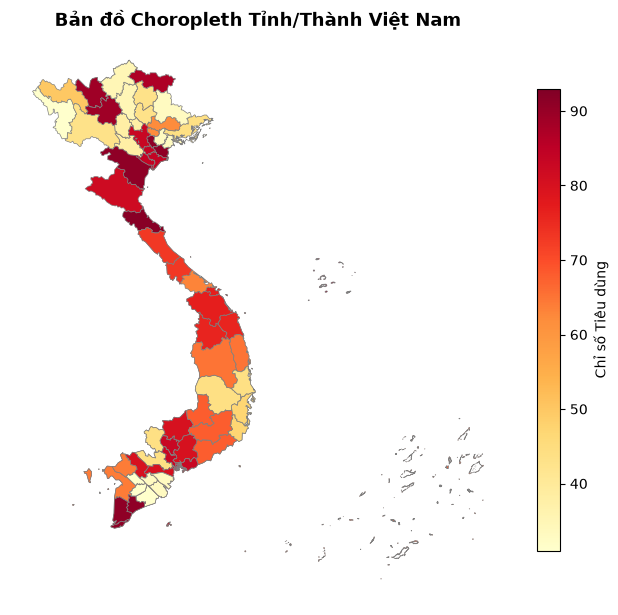

In [21]:
url_tinh_thanh = "d:/ttdltq_learn/vn_geo.json"
vietnam_map = gpd.read_file(url_tinh_thanh)

name_col = 'Name' if 'Name' in vietnam_map.columns else 'name'

np.random.seed(42)
data_df = pd.DataFrame({
    name_col: vietnam_map[name_col],
    'Chi_so': np.random.randint(30, 100, size=len(vietnam_map))
})

merged_map = vietnam_map.merge(data_df, on=name_col)

fig, ax = plt.subplots(figsize=(8, 12))
merged_map.plot(
    column='Chi_so',
    cmap='YlOrRd',
    linewidth=0.5,
    ax=ax,
    edgecolor='0.5',
    legend=True,
    legend_kwds={'label': "Chỉ số Tiêu dùng", 'shrink': 0.5}
)

plt.title('Bản đồ Choropleth Tỉnh/Thành Việt Nam', fontsize=13, weight='bold')
plt.axis('off')
plt.show()